# 03 · Descriptive statistics (Person 3)

**Question (RQ1):** Which EU institutions and venues lead research on AI in education, and has that changed since 2020?

**Input files** (from Person 1 and Person 2, not changed here):
- `works_layers.csv`: one row = one paper
- `authorships_layers.csv`: one row = one author on one paper, with the author's institution

**Output:** charts go to `outputs/person3/figures/`, tables to `outputs/person3/tables/`.

**Two ways of counting a paper with several institutions:**
- *Full counting:* every institution gets 1 paper.
- *Fractional counting:* the paper is shared, e.g. 3 institutions get 1/3 each.

## Setup: load libraries and data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Find the data: project folder, or the same folder (e.g. Google Colab)
if Path("../../collecte_cleaning/data/processed/works_layers.csv").exists():
    data_folder = Path("../../collecte_cleaning/data/processed")
    out_folder = Path("../outputs/person3")
elif Path("../data/processed/works_layers.csv").exists():
    data_folder = Path("../data/processed")
    out_folder = Path("../outputs/person3")
else:
    data_folder = Path(".")
    out_folder = Path("outputs/person3")

fig_folder = out_folder / "figures"
tab_folder = out_folder / "tables"
fig_folder.mkdir(parents=True, exist_ok=True)
tab_folder.mkdir(parents=True, exist_ok=True)

# Read the two files
works = pd.read_csv(data_folder / "works_layers.csv")
authors = pd.read_csv(data_folder / "authorships_layers.csv")

print("Papers:", len(works))
print("Author rows:", len(authors))
print("Papers in STRICT:", works["in_strict"].sum())

Papers: 10208
Author rows: 50726
Papers in STRICT: 5927


## Step 1: Make the counting tables

Problem: if two authors from the same university write one paper, that university appears twice.
So we keep **one row per paper and institution**, and **one row per paper and country**.

In [2]:
# One row per paper + institution (rows without an institution are removed)
paper_inst = authors.dropna(subset=["institution_id"])
paper_inst = paper_inst.drop_duplicates(subset=["work_id", "institution_id"]).copy()

# How many institutions does each paper have?
inst_per_paper = paper_inst.groupby("work_id").size()

# Fractional credit: 1 divided by the number of institutions on that paper
paper_inst["fraction"] = 1 / paper_inst["work_id"].map(inst_per_paper)

# Add the publication year from the papers table (in_strict is already in the authors file)
paper_inst = paper_inst.merge(works[["work_id", "year"]], on="work_id")

# One row per paper + country
paper_country = authors.dropna(subset=["institution_country"])
paper_country = paper_country.drop_duplicates(subset=["work_id", "institution_country"])

# Number of institutions on each paper (0 if none recorded)
works["n_inst"] = works["work_id"].map(inst_per_paper).fillna(0)

print("Author rows without institution:", round(authors["institution_id"].isna().mean() * 100, 1), "%")
print("Paper + institution rows:", len(paper_inst))
print("Paper + country rows:", len(paper_country))

Author rows without institution: 5.2 %
Paper + institution rows: 25157
Paper + country rows: 16822


## Step 2: What kind of papers do we have?

In [3]:
# Document types, ALL and STRICT
types = pd.DataFrame({
    "ALL": works["type"].value_counts(),
    "STRICT": works[works["in_strict"]]["type"].value_counts(),
}).fillna(0).astype(int)
types.to_csv(tab_folder / "t1_document_types.csv")
print(types)

# Main research field of each paper (share in %)
fields = (works["field"].value_counts(normalize=True) * 100).round(1).head(8)
fields.to_csv(tab_folder / "t2_fields.csv")
print()
print(fields)

                   ALL  STRICT
type                          
article           5777    3954
book-chapter       629     143
conference-paper  2963    1539
preprint           499       0
review             340     291

field
Computer Science                       63.4
Medicine                               10.1
Social Sciences                        10.1
Psychology                              4.8
Arts and Humanities                     2.6
Engineering                             2.5
Decision Sciences                       1.6
Business, Management and Accounting     1.2
Name: proportion, dtype: float64


**What it shows:** 57% are journal articles and 29% conference papers. OpenAlex puts 63% of papers in Computer Science; Social Sciences and Medicine (mostly medical education) have about 10% each. So the field looks more technical than educational, which matters when we interpret who "leads".

## Step 3: Papers per year

       ALL  STRICT
year              
2020   471     299
2021   562     360
2022   637     421
2023  1316     787
2024  2730    1661
2025  4492    2399


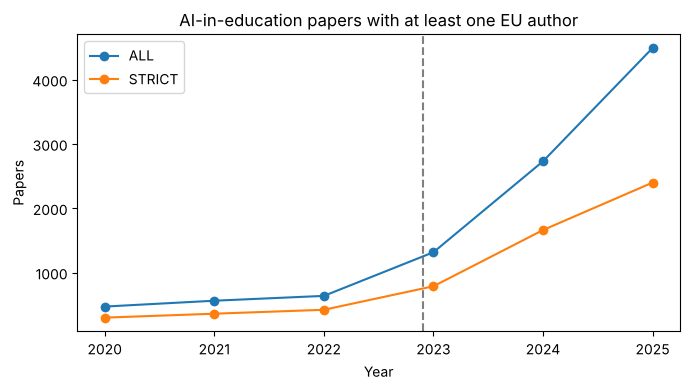

In [4]:
per_year = pd.DataFrame({
    "ALL": works.groupby("year").size(),
    "STRICT": works[works["in_strict"]].groupby("year").size(),
})
per_year.to_csv(tab_folder / "t3_papers_per_year.csv")
print(per_year)

# Line chart
per_year.plot(marker="o", figsize=(7, 4))
plt.axvline(2022.9, color="grey", linestyle="--")   # ChatGPT release, Nov 2022
plt.title("AI-in-education papers with at least one EU author")
plt.xlabel("Year")
plt.ylabel("Papers")
plt.tight_layout()
plt.savefig(fig_folder / "f1_papers_per_year.png")
plt.show()

**What it shows:** 471 papers in 2020 → 4,492 in 2025. Slow growth until 2022, then output doubled in both 2023 and 2024, right after ChatGPT (dashed line). The timing fits, but this does not prove ChatGPT caused it.

**Careful:** 2025 is still being added to OpenAlex and Scopus, so 2025 numbers can still change.

## Step 4: Countries

                     papers  percent of all papers
institution_country                               
DE                     1764                   17.3
ES                     1555                   15.2
IT                     1140                   11.2
FR                      628                    6.2
GR                      623                    6.1
FI                      586                    5.7
NL                      562                    5.5
PL                      539                    5.3
PT                      482                    4.7
SE                      476                    4.7
RO                      473                    4.6
IE                      352                    3.4
AT                      299                    2.9
BG                      298                    2.9
HU                      271                    2.7


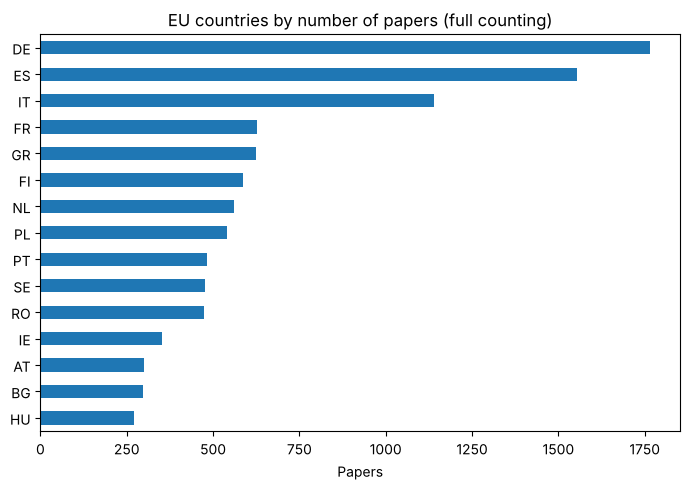

In [5]:
# Only EU countries; count each paper once per country
eu = paper_country[paper_country["is_eu"]]
countries = eu.groupby("institution_country")["work_id"].nunique().sort_values(ascending=False)

countries_table = pd.DataFrame({
    "papers": countries,
    "percent of all papers": (countries / len(works) * 100).round(1),
})
countries_table.to_csv(tab_folder / "t4_eu_countries.csv")
print(countries_table.head(15))

# Bar chart of the top 15
countries.head(15).sort_values().plot(kind="barh", figsize=(7, 5))
plt.title("EU countries by number of papers (full counting)")
plt.xlabel("Papers")
plt.ylabel("")
plt.tight_layout()
plt.savefig(fig_folder / "f2_eu_countries.png")
plt.show()

In [6]:
# Non-EU partner countries
non_eu = paper_country[~paper_country["is_eu"]]
partners = non_eu.groupby("institution_country")["work_id"].nunique().sort_values(ascending=False).head(10)
partners.to_csv(tab_folder / "t5_non_eu_partners.csv")
print(partners)

share = works["work_id"].isin(non_eu["work_id"]).mean() * 100
print()
print("Papers with at least one non-EU co-author:", round(share), "%")

institution_country
US    796
GB    552
CN    276
AU    249
CH    191
CA    186
IN    154
TR    132
NO    127
BR    115
Name: work_id, dtype: int64

Papers with at least one non-EU co-author: 30 %


**What it shows:** Germany (17% of papers), Spain (15%) and Italy (11%) lead. These are big countries, and we did not adjust for size. The most common non-EU partners are the United States and the United Kingdom; 30% of papers have a non-EU co-author.

## Step 5: Institutions, who leads?

In [7]:
# Only EU institutions
eu_inst = paper_inst[paper_inst["is_eu"]]

# Full counting: number of papers per institution
full = eu_inst.groupby(["institution_name", "institution_country"])["work_id"].nunique()

# Fractional counting: sum of the fractions
frac = eu_inst.groupby(["institution_name", "institution_country"])["fraction"].sum()

institutions = pd.DataFrame({"full": full, "fractional": frac.round(1)})
institutions = institutions.sort_values("full", ascending=False)
institutions.to_csv(tab_folder / "t6_institutions_all.csv")

print("Number of EU institutions:", len(institutions))
print(institutions.head(15))

Number of EU institutions: 2740
                                                                  full  \
institution_name                             institution_country         
University of Eastern Finland                FI                    169   
Technical University of Munich               DE                    115   
Ludwig-Maximilians-Universität München       DE                    109   
University of Oulu                           FI                     90   
University College Dublin                    IE                     90   
Centre National de la Recherche Scientifique FR                     89   
University of Zagreb                         HR                     85   
Universidad de Salamanca                     ES                     81   
Near East University                         CY                     78   
KTH Royal Institute of Technology            SE                     76   
University of Helsinki                       FI                     74   
Aalto 

In [8]:
# Same table for the STRICT layer only
strict_inst = eu_inst[eu_inst["in_strict"]]
strict_table = pd.DataFrame({
    "full": strict_inst.groupby(["institution_name", "institution_country"])["work_id"].nunique(),
    "fractional": strict_inst.groupby(["institution_name", "institution_country"])["fraction"].sum().round(1),
}).sort_values("full", ascending=False)
strict_table.to_csv(tab_folder / "t7_institutions_strict.csv")

# How similar are the top-15 lists?
top_full = set(institutions.head(15).index)
top_frac = set(institutions.sort_values("fractional", ascending=False).head(15).index)
top_strict = set(strict_table.head(15).index)
print("Top 15 same in full and fractional:", len(top_full & top_frac), "of 15")
print("Top 15 same in ALL and STRICT:", len(top_full & top_strict), "of 15")

# Is the field concentrated in a few institutions?
top10_share = institutions["full"].head(10).sum() / institutions["full"].sum() * 100
one_paper = (institutions["full"] == 1).mean() * 100
print("Top 10 institutions hold", round(top10_share, 1), "% of all EU participations")
print(round(one_paper), "% of institutions have only 1 paper")

Top 15 same in full and fractional: 9 of 15
Top 15 same in ALL and STRICT: 11 of 15
Top 10 institutions hold 5.6 % of all EU participations
44 % of institutions have only 1 paper


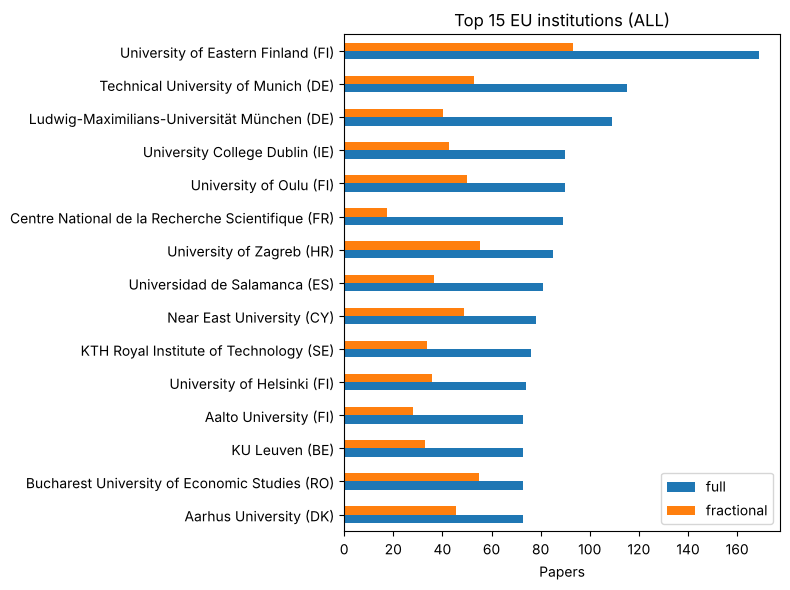

In [9]:
# Bar chart: top 15, full vs fractional
top15 = institutions.head(15).sort_values("full")
top15.index = [name + " (" + country + ")" for name, country in top15.index]
top15.plot(kind="barh", figsize=(8, 6))
plt.title("Top 15 EU institutions (ALL)")
plt.xlabel("Papers")
plt.tight_layout()
plt.savefig(fig_folder / "f3_top_institutions.png")
plt.show()

**What it shows:** the University of Eastern Finland clearly leads (169 papers full, 93 fractional). Below it, the order depends on the counting rule: only 9 of the top 15 are the same. Institutions that join many group papers drop with fractional counting (CNRS 89 → 18, LMU Munich 109 → 40). The STRICT layer changes less (11 of 15 the same). The field is spread out: the top 10 hold under 6%, and 44% of institutions have only one paper.

**Careful:**
- CNRS is a national organisation with many labs, not one university.
- Near East University is coded Cyprus (CY) by OpenAlex but is in the northern part of the island, where EU law is suspended.
- 5% of author rows have no institution, so some institutions are missing.

## Step 6: Did the leaders change after 2022?

In [10]:
# Split into two periods
early = eu_inst[eu_inst["year"] <= 2022]
late = eu_inst[eu_inst["year"] >= 2023]
papers_early = (works["year"] <= 2022).sum()
papers_late = (works["year"] >= 2023).sum()

top_early = early.groupby("institution_name")["work_id"].nunique().sort_values(ascending=False).head(10)
top_late = late.groupby("institution_name")["work_id"].nunique().sort_values(ascending=False).head(10)

# Use percent of the period's papers, because the late period is much bigger
period_table = pd.DataFrame({
    "2020-2022": top_early.index,
    "% early": (top_early.values / papers_early * 100).round(1),
    "2023-2025": top_late.index,
    "% late": (top_late.values / papers_late * 100).round(1),
})
period_table.to_csv(tab_folder / "t8_top10_by_period.csv", index=False)
print("Papers 2020-2022:", papers_early, "| papers 2023-2025:", papers_late)
print(period_table)
print()
print("In the top 10 both times:", set(top_early.index) & set(top_late.index))

Papers 2020-2022: 1670 | papers 2023-2025: 8538
                                      2020-2022  % early  \
0                 University of Eastern Finland      3.1   
1              Universidad Carlos III de Madrid      2.2   
2  Centre National de la Recherche Scientifique      1.8   
3                                     KU Leuven      1.4   
4                      Universidad de Salamanca      1.3   
5             KTH Royal Institute of Technology      1.3   
6                             Aarhus University      1.2   
7                     Universidad de Valladolid      1.1   
8                         Universidad de Murcia      1.1   
9             Universidad Politécnica de Madrid      1.1   

                                  2023-2025  % late  
0             University of Eastern Finland     1.4  
1            Technical University of Munich     1.2  
2    Ludwig-Maximilians-Universität München     1.1  
3                 University College Dublin     0.9  
4                    

**What it shows:** only the University of Eastern Finland is in the top 10 in both periods. Before 2023, 5 of the top 10 were Spanish; after 2022, German, Finnish, Irish, Croatian, Romanian and Greek universities came in. Even the leader's share fell (3.1% → 1.4%): the field spread out as it grew.

**Careful:** the early period is small (1,670 papers), so those rankings rest on small numbers.

## Step 7: Venues (where papers are published)

Papers in repositories: 9.0 %
source_name
Lecture notes in computer science                                                     210
Lecture notes in networks and systems                                                 141
Education Sciences                                                                    116
Communications in computer and information science                                    115
Applied Sciences                                                                      111
IEEE Global Engineering Education Conference (EDUCON)                                  92
Computers and Education Artificial Intelligence                                        83
IEEE Access                                                                            73
Sustainability                                                                         71
Frontiers in Education                                                                 70
Advances in computational intelligence and robotics book s

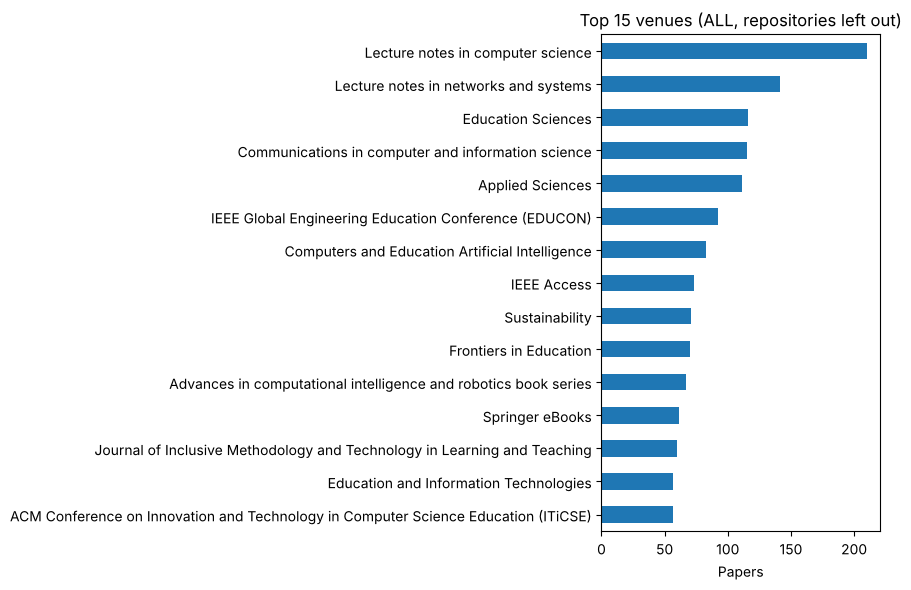

In [11]:
# Repositories (arXiv, HAL, Zenodo...) are not publication venues, so we leave them out
is_repo = works["is_repository"] | (works["source_type"] == "repository")
print("Papers in repositories:", round(is_repo.mean() * 100, 1), "%")

venues = works[~is_repo].groupby("source_name").size().sort_values(ascending=False).head(15)
venues.to_csv(tab_folder / "t9_top_venues_all.csv")
print(venues)

strict_venues = works[works["in_strict"]].groupby("source_name").size().sort_values(ascending=False).head(15)
strict_venues.to_csv(tab_folder / "t10_top_venues_strict.csv")

venues.sort_values().plot(kind="barh", figsize=(9, 6))
plt.title("Top 15 venues (ALL, repositories left out)")
plt.xlabel("Papers")
plt.ylabel("")
plt.tight_layout()
plt.savefig(fig_folder / "f4_top_venues.png")
plt.show()

**What it shows:** no venue holds more than about 2% of papers. The biggest are computer-science book series (Lecture Notes in Computer Science, 210 papers), open-access journals (Education Sciences, Applied Sciences), the IEEE EDUCON conference and the journal *Computers and Education: Artificial Intelligence*. Repositories hold about 9% of papers.

## Step 8: Citations

In [12]:
cites = works["cited_by_count"]
print("Mean citations:", round(cites.mean(), 1))
print("Median citations:", cites.median())
print("Papers with 0 citations:", round((cites == 0).mean() * 100), "%")

# Share of all citations that go to the top 1% of papers
top1 = cites.sort_values(ascending=False).head(len(cites) // 100)
print("Top 1% of papers get", round(top1.sum() / cites.sum() * 100), "% of all citations")

by_year = works.groupby("year")["cited_by_count"].agg(["mean", "median"]).round(1)
by_year.to_csv(tab_folder / "t11_citations_by_year.csv")
print()
print(by_year)

Mean citations: 19.4
Median citations: 3.0
Papers with 0 citations: 27 %
Top 1% of papers get 31 % of all citations

      mean  median
year              
2020  40.9    12.0
2021  34.1     9.0
2022  36.4     8.0
2023  45.2     7.0
2024  18.1     5.0
2025   6.0     1.0


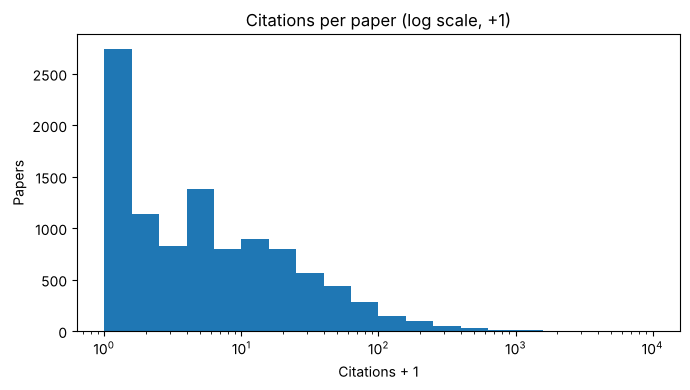

In [13]:
# Histogram on a log scale (+1 so that papers with 0 citations are included)
plt.figure(figsize=(7, 4))
bins = [10 ** (i / 5) for i in range(21)]   # equal-width bins on a log scale, from 1 to 10,000
plt.hist(cites + 1, bins=bins)
plt.xscale("log")
plt.title("Citations per paper (log scale, +1)")
plt.xlabel("Citations + 1")
plt.ylabel("Papers")
plt.tight_layout()
plt.savefig(fig_folder / "f5_citations_hist.png")
plt.show()

**What it shows:** citations are very unequal. The mean (19.4) is much bigger than the median (3), because a few papers have thousands of citations. So the **median** describes a typical paper better (Week 5: mean > median = long right tail). The top 1% of papers get 31% of all citations, and 27% of papers have none.

**Careful:** old papers had more time to be cited, so do not compare raw citations across years.

## Step 9: Collaboration

2+ institutions    54.0
2+ countries       36.0
non-EU partner     30.0
dtype: float64

      2+ institutions  2+ countries  non-EU partner
year                                               
2020             56.0          41.0            34.0
2021             56.0          38.0            30.0
2022             60.0          40.0            34.0
2023             58.0          37.0            32.0
2024             53.0          35.0            29.0
2025             52.0          34.0            29.0

Median authors per paper: 3.0


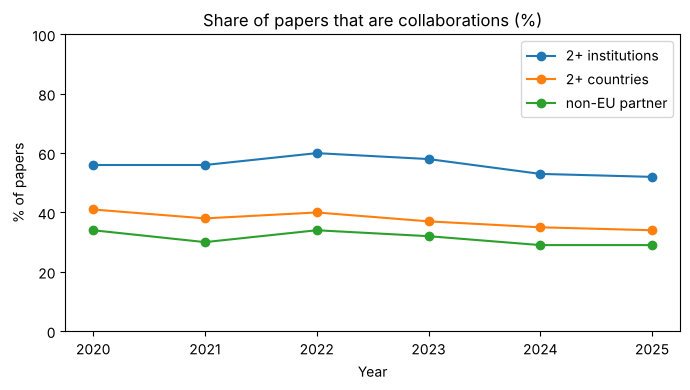

In [14]:
works["2+ institutions"] = works["n_inst"] > 1
works["2+ countries"] = works["n_countries"] > 1
works["non-EU partner"] = works["work_id"].isin(non_eu["work_id"])

columns = ["2+ institutions", "2+ countries", "non-EU partner"]
collab = (works.groupby("year")[columns].mean() * 100).round()
collab.to_csv(tab_folder / "t12_collaboration_by_year.csv")
print((works[columns].mean() * 100).round())   # all years together
print()
print(collab)
print()
print("Median authors per paper:", works["n_authors"].median())

collab.plot(marker="o", figsize=(7, 4))
plt.ylim(0, 100)
plt.title("Share of papers that are collaborations (%)")
plt.xlabel("Year")
plt.ylabel("% of papers")
plt.tight_layout()
plt.savefig(fig_folder / "f6_collaboration.png")
plt.show()

**What it shows:** 54% of papers have 2+ institutions, 36% have 2+ countries, and 30% have a non-EU partner. The median paper has 3 authors. Collaboration fell slightly as the field grew (2+ institutions: 60% in 2022 → 52% in 2025).

**Careful:** papers with missing institutions look like single-institution papers, so collaboration is slightly underestimated.

## Summary

1. **Growth:** 471 papers (2020) → 4,492 (2025); fast growth from 2023.
2. **Countries:** Germany, Spain and Italy lead (not adjusted for size).
3. **Institutions:** University of Eastern Finland leads in every check; the rest depends on the counting rule and changed a lot after 2022.
4. **Venues:** no venue dominates (max about 2%).
5. **Citations:** very skewed (median 3, mean 19.4).
6. **Collaboration:** 54% multi-institution, 36% international.

## Limitations
- Results depend on the keyword search (not hand-checked in this section).
- 5% of author rows have no institution.
- Full and fractional counting give different rankings.
- Counts are not adjusted for country size.
- "EU" follows OpenAlex country codes (e.g. Near East University).
- CNRS counts as one institution.
- 2025 is incomplete, and new papers had little time to be cited.